In [36]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


In [37]:
df = pd.read_csv('Food_Delivery_Times.csv')

In [38]:
df.head()

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68


In [39]:
# Check for missing values in each column
print("Missing values per column before cleaning:")
display(df.isnull().sum())

Missing values per column before cleaning:


,0
Order_ID,0
Distance_km,0
Weather,30
Traffic_Level,30
Time_of_Day,30
Vehicle_Type,0
Preparation_Time_min,0
Courier_Experience_yrs,30
Delivery_Time_min,0


In [40]:
# Fill null values appropriately
# For numerical columns, we can fill with the median to avoid outlier bias
# For categorical columns, we can fill with the mode (most frequent value)

for col in df.columns:
    if df[col].isnull().any():
        if df[col].dtype in ['int64', 'float64']:
            fill_value = df[col].median()
            df[col] = df[col].fillna(fill_value)
            print(f"Filled missing values in numerical column '{col}' with median: {fill_value}")
        else:
            fill_value = df[col].mode()[0]
            df[col] = df[col].fillna(fill_value)
            print(f"Filled missing values in categorical column '{col}' with mode: {fill_value}")

# Confirm that no null values remain
print("\nMissing values per column after cleaning:")
display(df.isnull().sum())

Filled missing values in categorical column 'Weather' with mode: Clear
Filled missing values in categorical column 'Traffic_Level' with mode: Medium
Filled missing values in categorical column 'Time_of_Day' with mode: Morning
Filled missing values in numerical column 'Courier_Experience_yrs' with median: 5.0

Missing values per column after cleaning:


,0
Order_ID,0
Distance_km,0
Weather,0
Traffic_Level,0
Time_of_Day,0
Vehicle_Type,0
Preparation_Time_min,0
Courier_Experience_yrs,0
Delivery_Time_min,0


In [41]:
df.drop('Order_ID',axis = 1, inplace= True)

In [42]:
df.head()

,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,19.03,Clear,Low,Morning,Bike,16,5.0,68


In [43]:
df.describe()

,Distance_km,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,10.059970,16.982000,4.592000,56.732000
std,5.696656,7.204553,2.871198,22.070915
min,0.590000,5.000000,0.000000,8.000000
25%,5.105000,11.000000,2.000000,41.000000
50%,10.190000,17.000000,5.000000,55.500000
75%,15.017500,23.000000,7.000000,71.000000
max,19.990000,29.000000,9.000000,153.000000


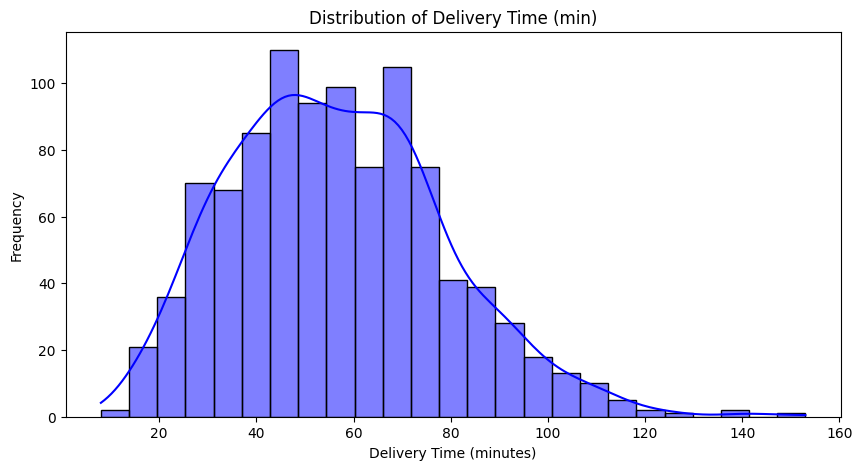

In [44]:
# 1. Distribution of the Target Variable
plt.figure(figsize=(10, 5))
sns.histplot(df['Delivery_Time_min'], kde=True, color='blue')
plt.title('Distribution of Delivery Time (min)')
plt.xlabel('Delivery Time (minutes)')
plt.ylabel('Frequency')
plt.show()

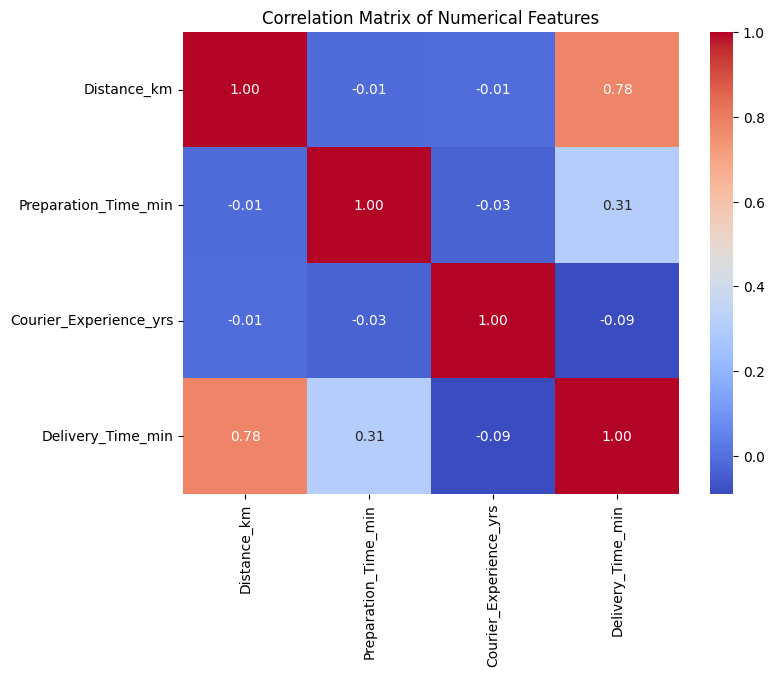

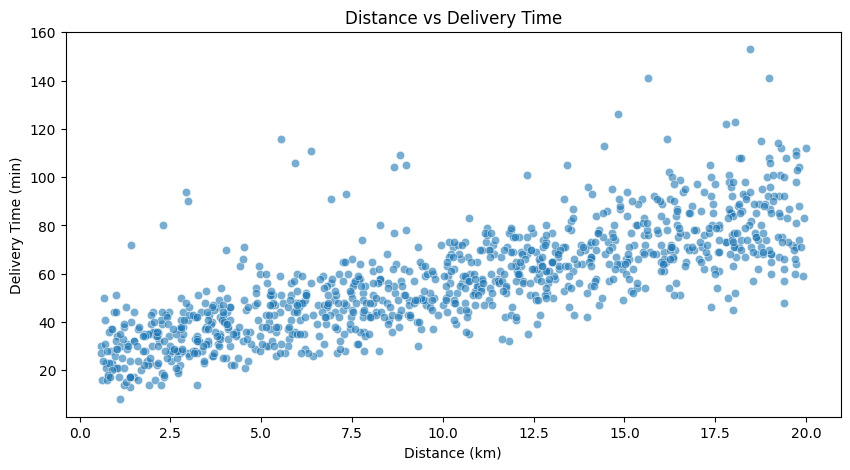

In [45]:
# 2. Relationships with Numerical Features (Correlation & Scatter Plots)
numerical_cols = ['Distance_km', 'Preparation_Time_min', 'Courier_Experience_yrs', 'Delivery_Time_min']

plt.figure(figsize=(8, 6))
sns.heatmap(df[numerical_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Numerical Features')
plt.show()

# Scatter plot for Distance vs Delivery Time
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df, x='Distance_km', y='Delivery_Time_min', alpha=0.6)
plt.title('Distance vs Delivery Time')
plt.xlabel('Distance (km)')
plt.ylabel('Delivery Time (min)')
plt.show()

/tmp/ipykernel_1159/1396809549.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[i], data=df, x=col, y='Delivery_Time_min', palette='Set2')
/tmp/ipykernel_1159/1396809549.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=45)
/tmp/ipykernel_1159/1396809549.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[i], data=df, x=col, y='Delivery_Time_min', palette='Set2')
/tmp/ipykernel_1159/1396809549.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.


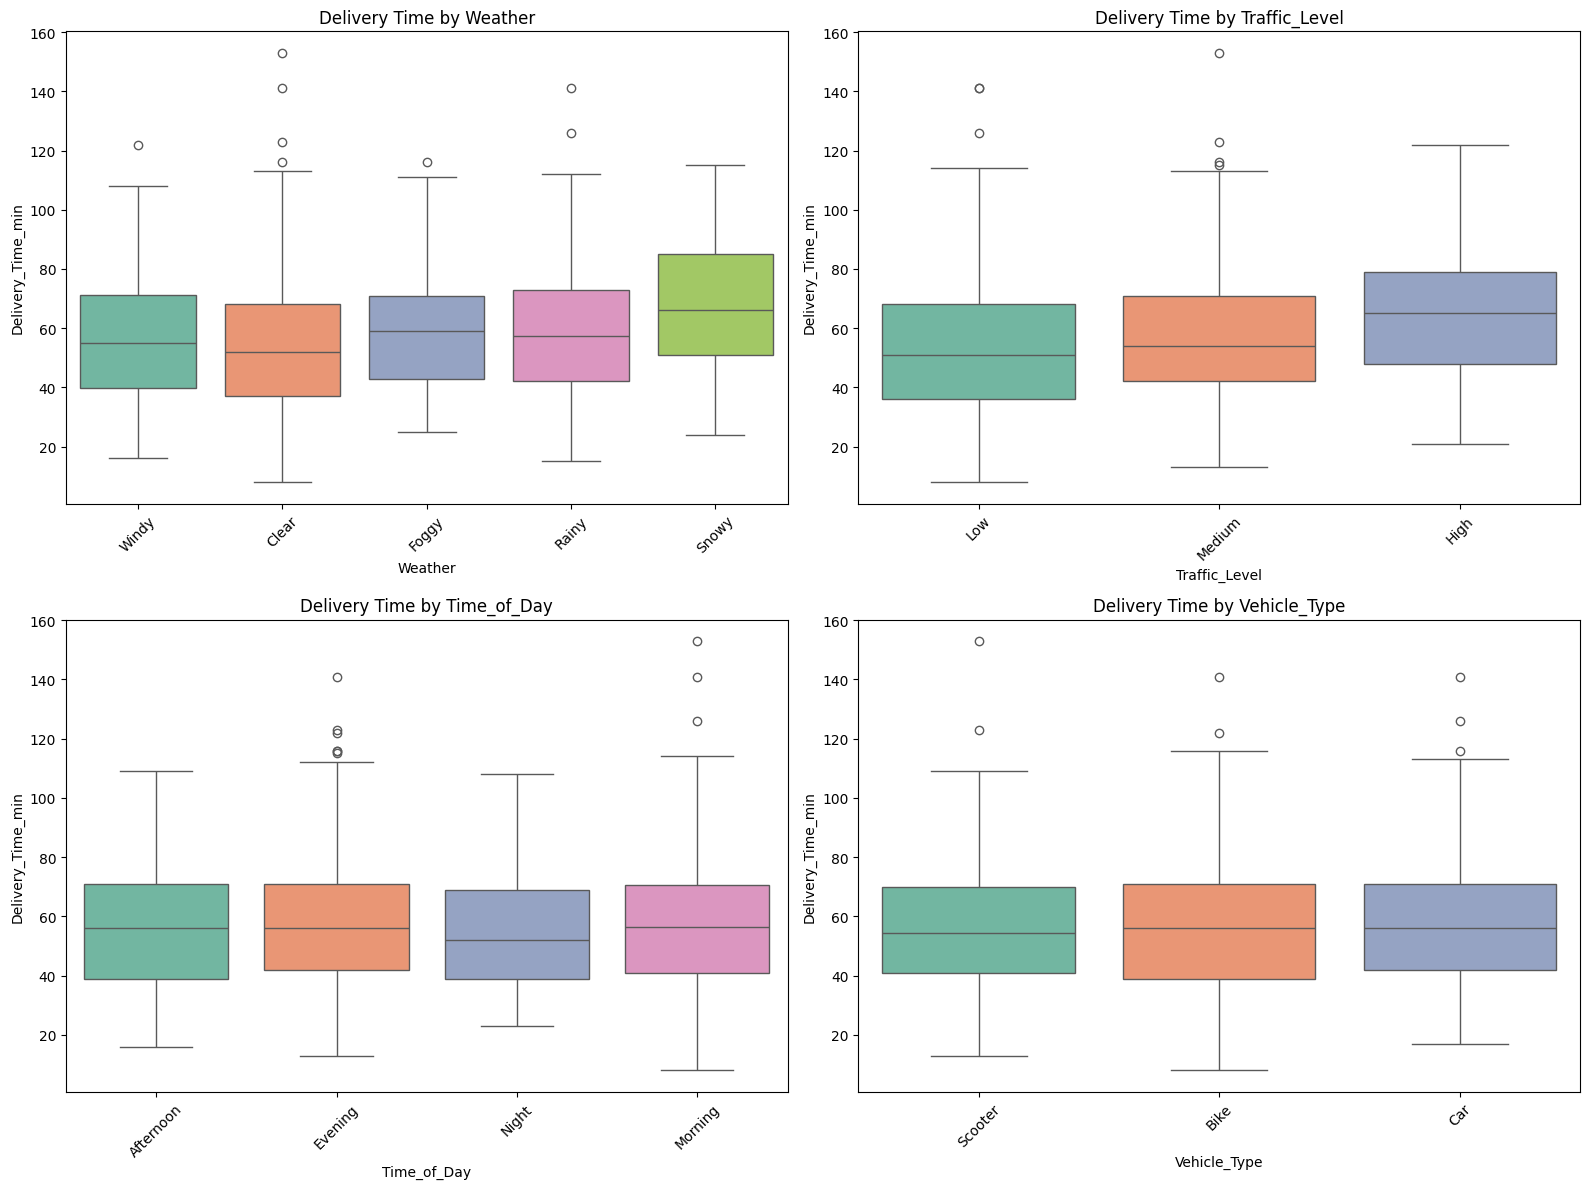

In [46]:
# 3. Relationships with Categorical Features (Boxplots)
categorical_cols = ['Weather', 'Traffic_Level', 'Time_of_Day', 'Vehicle_Type']

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(categorical_cols):
    sns.boxplot(ax=axes[i], data=df, x=col, y='Delivery_Time_min', palette='Set2')
    axes[i].set_title(f'Delivery Time by {col}')
    axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=45)

plt.tight_layout()
plt.show()

In [47]:
from scipy import stats

print("=== Statistical Testing for Feature Selection ===\n")

# 1. Testing Numerical Features using Pearson Correlation
numerical_features = ['Distance_km', 'Preparation_Time_min', 'Courier_Experience_yrs']
print("--- Numerical Features (Correlation with Delivery_Time_min) ---")
for col in numerical_features:
    corr_coef, p_val = stats.pearsonr(df[col], df['Delivery_Time_min'])
    significance = "Significant" if p_val < 0.05 else "Not Significant"
    print(f"{col:25} -> Correlation: {corr_coef:6.3f} | p-value: {p_val:8.2e} ({significance})")

=== Statistical Testing for Feature Selection ===

--- Numerical Features (Correlation with Delivery_Time_min) ---
Distance_km               -> Correlation:  0.781 | p-value: 2.98e-206 (Significant)
Preparation_Time_min      -> Correlation:  0.307 | p-value: 2.55e-23 (Significant)
Courier_Experience_yrs    -> Correlation: -0.089 | p-value: 4.80e-03 (Significant)


In [48]:
# 2. Testing Categorical Features using One-way ANOVA
categorical_features = ['Weather', 'Traffic_Level', 'Time_of_Day', 'Vehicle_Type']
print("\n--- Categorical Features (One-Way ANOVA with Delivery_Time_min) ---")
for col in categorical_features:
    # Group the delivery times by each category
    groups = [group['Delivery_Time_min'].values for name, group in df.groupby(col)]
    f_stat, p_val = stats.f_oneway(*groups)
    significance = "Significant" if p_val < 0.05 else "Not Significant"
    print(f"{col:25} -> F-statistic: {f_stat:6.2f} | p-value: {p_val:8.2e} ({significance})")


--- Categorical Features (One-Way ANOVA with Delivery_Time_min) ---
Weather                   -> F-statistic:  10.50 | p-value: 2.47e-08 (Significant)
Traffic_Level             -> F-statistic:  19.75 | p-value: 3.87e-09 (Significant)
Time_of_Day               -> F-statistic:   0.35 | p-value: 7.92e-01 (Not Significant)
Vehicle_Type              -> F-statistic:   0.59 | p-value: 5.55e-01 (Not Significant)


In [49]:
from sklearn.preprocessing import LabelEncoder

# Create a copy of the dataframe
df_encoded = df.copy()

# Categorical columns
categorical_cols = [
    'Weather',
    'Traffic_Level',
    'Time_of_Day',
    'Vehicle_Type'
]

# Store a separate encoder for each categorical column
encoders = {}

for col in categorical_cols:
    encoder = LabelEncoder()

    df_encoded[col] = encoder.fit_transform(
        df_encoded[col].astype(str)
    )

    encoders[col] = encoder

    print(f"\nColumn: {col}")
    print("Categories:", list(encoder.classes_))

print("\nEncoding completed successfully!")

display(df_encoded.head())


Column: Weather
Categories: ['Clear', 'Foggy', 'Rainy', 'Snowy', 'Windy']

Column: Traffic_Level
Categories: ['High', 'Low', 'Medium']

Column: Time_of_Day
Categories: ['Afternoon', 'Evening', 'Morning', 'Night']

Column: Vehicle_Type
Categories: ['Bike', 'Car', 'Scooter']

Encoding completed successfully!


,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,7.93,4,1,0,2,12,1.0,43
1,16.42,0,2,1,0,20,2.0,84
2,9.52,1,1,3,2,28,1.0,59
3,7.44,2,2,0,2,5,1.0,37
4,19.03,0,1,2,0,16,5.0,68


In [50]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
X = df_encoded.drop('Delivery_Time_min', axis=1)
y = df_encoded['Delivery_Time_min']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(800, 7) (200, 7) (800,) (200,)


In [51]:
from sklearn.tree import DecisionTreeRegressor
dtc_model = DecisionTreeRegressor(random_state = 42)
dtc_model.fit(X_train, y_train)
y_pred_dtc = dtc_model.predict(X_test)
dtc_model

DecisionTreeRegressor(random_state=42)

In [52]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
mse = mean_squared_error(y_test, y_pred_dtc)
mae = mean_absolute_error(y_test, y_pred_dtc)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_dtc)

In [53]:
print("Mean Squared Error (MSE):", mse)
print("Mean Absolute Error (MAE):", mae)
print("Root Mean Squared Error (RMSE):", rmse)
print("R-squared (R2) Score:", r2)

Mean Squared Error (MSE): 226.82
Mean Absolute Error (MAE): 10.56
Root Mean Squared Error (RMSE): 15.060544478869282
R-squared (R2) Score: 0.4939617366848571


In [54]:
# Calculate predictions and metrics on the training set to check for overfitting/underfitting
y_pred_train_dtc = dtc_model.predict(X_train)

mse_train = mean_squared_error(y_train, y_pred_train_dtc)
mae_train = mean_absolute_error(y_train, y_pred_train_dtc)
rmse_train = np.sqrt(mse_train)
r2_train = r2_score(y_train, y_pred_train_dtc)

print("=== Training Metrics ===")
print("Train Mean Squared Error (MSE):", mse_train)
print("Train Mean Absolute Error (MAE):", mae_train)
print("Train Root Mean Squared Error (RMSE):", rmse_train)
print("Train R-squared (R2) Score:", r2_train)

print("\n=== Test Metrics (For Comparison) ===")
print("Test R-squared (R2) Score:", r2)

=== Training Metrics ===
Train Mean Squared Error (MSE): 0.0
Train Mean Absolute Error (MAE): 0.0
Train Root Mean Squared Error (RMSE): 0.0
Train R-squared (R2) Score: 1.0

=== Test Metrics (For Comparison) ===
Test R-squared (R2) Score: 0.4939617366848571


In [55]:
from sklearn.ensemble import RandomForestRegressor

# Initialize the Random Forest Regressor with default parameters
rf_model = RandomForestRegressor(random_state=42)

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions
y_pred_train_rf = rf_model.predict(X_train)
y_pred_test_rf = rf_model.predict(X_test)

# Calculate metrics for the training set
mse_train_rf = mean_squared_error(y_train, y_pred_train_rf)
rmse_train_rf = np.sqrt(mse_train_rf)
r2_train_rf = r2_score(y_train, y_pred_train_rf)

# Calculate metrics for the test set
mse_test_rf = mean_squared_error(y_test, y_pred_test_rf)
rmse_test_rf = np.sqrt(mse_test_rf)
r2_test_rf = r2_score(y_test, y_pred_test_rf)

print("=== Random Forest Regressor (Default Parameters) ===")
print(f"Train RMSE: {rmse_train_rf:.4f} | Train R2: {r2_train_rf:.4f}")
print(f"Test RMSE:  {rmse_test_rf:.4f}  | Test R2:  {r2_test_rf:.4f}")

=== Random Forest Regressor (Default Parameters) ===
Train RMSE: 4.7612 | Train R2: 0.9543
Test RMSE:  10.0058  | Test R2:  0.7766


In [56]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Define the hyperparameter grid
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# Initialize GridSearchCV with the Random Forest model
rf_grid = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1,
    verbose=1
)

# Fit GridSearchCV to the training data
rf_grid.fit(X_train, y_train)

# Get the best estimator and parameters
best_rf = rf_grid.best_estimator_
print("=== Best Parameters Found ===")
print(rf_grid.best_params_)

# Evaluate the tuned model
y_pred_train_tuned = best_rf.predict(X_train)
y_pred_test_tuned = best_rf.predict(X_test)

# Calculate metrics
rmse_train_tuned = np.sqrt(mean_squared_error(y_train, y_pred_train_tuned))
r2_train_tuned = r2_score(y_train, y_pred_train_tuned)

rmse_test_tuned = np.sqrt(mean_squared_error(y_test, y_pred_test_tuned))
r2_test_tuned = r2_score(y_test, y_pred_test_tuned)

print("\n=== Tuned Random Forest Regressor Metrics ===")
print(f"Train RMSE: {rmse_train_tuned:.4f} | Train R2: {r2_train_tuned:.4f}")
print(f"Test RMSE:  {rmse_test_tuned:.4f}  | Test R2:  {r2_test_tuned:.4f}")

Fitting 5 folds for each of 108 candidates, totalling 540 fits
=== Best Parameters Found ===
{'max_depth': None, 'min_samples_leaf': 4, 'min_samples_split': 10, 'n_estimators': 200}

=== Tuned Random Forest Regressor Metrics ===
Train RMSE: 8.8299 | Train R2: 0.8427
Test RMSE:  9.8240  | Test R2:  0.7847


In [57]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Instantiate the optimized Random Forest model using the best parameters
optimized_rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=None,
    min_samples_split=10,
    min_samples_leaf=4,
    random_state=42
)

# Train the optimized model on the training set
optimized_rf.fit(X_train, y_train)

# Predict on train and test sets
y_pred_train_opt = optimized_rf.predict(X_train)
y_pred_test_opt = optimized_rf.predict(X_test)

# Calculate evaluation metrics
mse_train_opt = mean_squared_error(y_train, y_pred_train_opt)
rmse_train_opt = np.sqrt(mse_train_opt)
mae_train_opt = mean_absolute_error(y_train, y_pred_train_opt)
r2_train_opt = r2_score(y_train, y_pred_train_opt)

mse_test_opt = mean_squared_error(y_test, y_pred_test_opt)
rmse_test_opt = np.sqrt(mse_test_opt)
mae_test_opt = mean_absolute_error(y_test, y_pred_test_opt)
r2_test_opt = r2_score(y_test, y_pred_test_opt)

print("=== Final Optimized Random Forest Regressor ===")
print("--- Training Metrics ---")
print(f"Train MSE:  {mse_train_opt:.4f}")
print(f"Train MAE:  {mae_train_opt:.4f}")
print(f"Train RMSE: {rmse_train_opt:.4f}")
print(f"Train R2:   {r2_train_opt:.4f}")

print("\n--- Test Metrics ---")
print(f"Test MSE:   {mse_test_opt:.4f}")
print(f"Test MAE:   {mae_test_opt:.4f}")
print(f"Test RMSE:  {rmse_test_opt:.4f}")
print(f"Test R2:    {r2_test_opt:.4f}")

=== Final Optimized Random Forest Regressor ===
--- Training Metrics ---
Train MSE:  77.9666
Train MAE:  5.5125
Train RMSE: 8.8299
Train R2:   0.8427

--- Test Metrics ---
Test MSE:   96.5115
Test MAE:   6.8536
Test RMSE:  9.8240
Test R2:    0.7847


In [59]:
import pickle

# Bundle the trained model and preprocessing information
model_bundle = {
    "model": optimized_rf,
    "encoders": encoders,
    "feature_columns": list(X.columns),
    "categorical_columns": categorical_cols,
    "target_column": "Delivery_Time_min"
}

# Save the complete bundle
with open("food_delivery_model.pkl", "wb") as file:
    pickle.dump(model_bundle, file)

print("Model bundle saved successfully!")
print("File: food_delivery_model.pkl")

print("\nSaved components:")
print("1. Optimized Random Forest model")
print("2. Four categorical encoders")
print("3. Feature column names and order")
print("4. Target column name")

Model bundle saved successfully!
File: food_delivery_model.pkl

Saved components:
1. Optimized Random Forest model
2. Four categorical encoders
3. Feature column names and order
4. Target column name


In [60]:
import pickle

with open("food_delivery_model.pkl", "rb") as file:
    saved_bundle = pickle.load(file)

print("Model:", type(saved_bundle["model"]))

print("\nFeature columns:")
print(saved_bundle["feature_columns"])

print("\nSaved encoders:")
for col, encoder in saved_bundle["encoders"].items():
    print(f"{col}: {list(encoder.classes_)}")

Model: <class 'sklearn.ensemble._forest.RandomForestRegressor'>

Feature columns:
['Distance_km', 'Weather', 'Traffic_Level', 'Time_of_Day', 'Vehicle_Type', 'Preparation_Time_min', 'Courier_Experience_yrs']

Saved encoders:
Weather: ['Clear', 'Foggy', 'Rainy', 'Snowy', 'Windy']
Traffic_Level: ['High', 'Low', 'Medium']
Time_of_Day: ['Afternoon', 'Evening', 'Morning', 'Night']
Vehicle_Type: ['Bike', 'Car', 'Scooter']
